In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens.lens import nfw
from gwlens.tools import halo
from gwlens.tools import plotting

plotting.apply_figure_style()

lens_redshift = 1.0
source_redshift = 2.0



Scaling ratio k: 0.09381658727578665
Dimensionless frequency w: 227.09519197345602


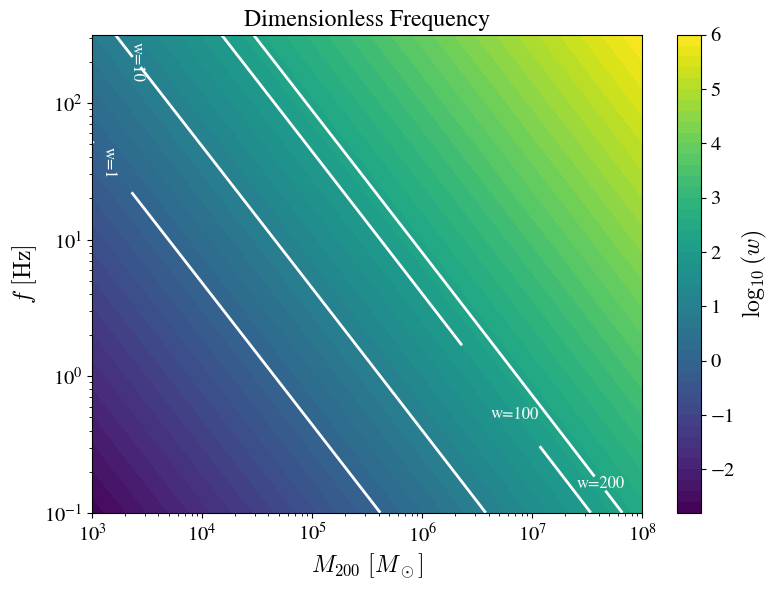

In [3]:
Halo = halo.NFW(M200=1e+5,zl=lens_redshift)
k = Halo.scaling_ratio(zs=2.0)
w = Halo.Dimensionless_Frequency(f=100.0)
print("Scaling ratio k:", k)
print("Dimensionless frequency w:", w)


# mass range
mass_values = np.logspace(3, 8, 200)   # solar masses

# frequency range
freq_values = np.logspace(-1, 2.5, 200)   # Hz

# create meshgrid
M_grid, F_grid = np.meshgrid(mass_values, freq_values)

# output array
W_grid = np.zeros_like(M_grid)

# compute w on the grid
for i in range(F_grid.shape[0]):
    for j in range(F_grid.shape[1]):

        Halo = halo.NFW(M200=M_grid[i, j], zl=1.0 )

        W_grid[i, j] = Halo.Dimensionless_Frequency(f=F_grid[i, j])

# contour plot
plt.figure(figsize=(8, 6))

contour = plt.contourf(M_grid, F_grid, np.log10(W_grid),levels=50,cmap='viridis')
# levels in actual w
w_levels = [1, 10, 100, 200]

# convert to log10-space
log_levels = np.log10(w_levels)

# contour lines
cs = plt.contour(M_grid,F_grid,np.log10(W_grid),levels=log_levels, colors='white',linewidths=2)

# labels on contours
plt.clabel(
    cs,
    fmt=lambda x: f"w={10**x:.0f}",
    inline=True,
    fontsize=12
)
# logarithmic axes
plt.xscale('log')
plt.yscale('log')

cbar = plt.colorbar(contour)
cbar.set_label(r'$\log_{10}(w)$')

plt.xlabel(r'$M_{200}\ [M_\odot]$')
plt.ylabel(r'$f\ [\mathrm{Hz}]$')

plt.title("Dimensionless Frequency")

plt.tight_layout()
plt.savefig("dimensionless_frequency.png", dpi=300)
plt.show()

### Time delay

In [4]:
nfw_lens = nfw.NFW1()
mass_values = np.logspace(3, 12, 200) 
H = halo.NFW(M200=1e+4, zl=lens_redshift)
effective_redshifted_lensmass = H.mass_enclosed_at_xrs(1.0).value * (1 + lens_redshift)
rs= np.float64(H.scaling_ratio(zs = source_redshift))
Timedelay = nfw_lens.Time_Delay(y1=0.05,y2=0,rs=rs,Ml=effective_redshifted_lensmass)



print("Time delay:", Timedelay)
print("Effective redshifted lens mass:", effective_redshifted_lensmass)
print("Scaling ratio:", H.scaling_ratio(zs = source_redshift))

Time delay: [<Quantity 0. s>, <Quantity 9.18579154e-08 s>, <Quantity 9.7528984e-07 s>]
Effective redshifted lens mass: 1119.7800425831554
Scaling ratio: 0.08250222815967376


/work/sreekanth/codes/GWLENS/gwlens/lens/nfw.py:348: RuntimeWarning: divide by zero encountered in arctanh
  h = np.arctanh(s) / s


### Image Positions verificationm

In [8]:
k = H.scaling_ratio(zs = source_redshift)
print(type(k))
print(k.unit)
images = nfw_lens.solve_images(0.05,0,0.8)
for img in images:
    print("Position:", img["position"], "Magnification:", img["magnification"])



<class 'astropy.units.quantity.Quantity'>

Position: (np.float64(0.17109586589394032), np.float64(0.0)) Magnification: 5.728632885582064
Position: (np.float64(1.254112811279772e-05), np.float64(0.0)) Magnification: -6.283048541685887e-08
Position: (np.float64(9.355908498047843e-06), np.float64(0.0)) Magnification: -3.4978145689276714e-08


In [17]:
H.scaling_ratio(zs = source_redshift)

<Quantity 0.26711564>

In [20]:
from lenstronomy.LensModel.lens_model import LensModel
from lenstronomy.LensModel.Solver.lens_equation_solver import LensEquationSolver


lens_model_list = ['NFW']
lens_model = LensModel(lens_model_list)

y1 = 0.01
y2 = 0.01

beta_ra = y1
beta_dec = y2

kwargs_nfw = { 'alpha_Rs': 1.0,'Rs':1.0, 'center_x': 0.0, 'center_y': 0.0}
solver = LensEquationSolver(lens_model)
kwargs_lens_list = [kwargs_nfw]
img_p = solver.image_position_from_source(beta_ra, beta_dec, kwargs_lens_list)

img_p

(array([ 0.71801581, -0.0009993 ]), array([ 0.71801581, -0.0009993 ]))

In [1]:
import numpy as np
from scipy.optimize import root_scalar

from lenstronomy.LensModel.lens_model import LensModel

# ============================================================
# YOUR PARAMETER
# ============================================================

k = 4.0

y = 0.05

# ============================================================
# LENSTRONOMY NFW
# ============================================================

lensModel = LensModel(['NFW'])

# ------------------------------------------------------------
# Choose arbitrary scale radius
# ------------------------------------------------------------

Rs = 1.0

# ------------------------------------------------------------
# Match normalization at r = Rs
# ------------------------------------------------------------

u = k * Rs

if u < 1:
    h = np.arctanh(np.sqrt(1-u*u))/np.sqrt(1-u*u)
else:
    h = np.arctan(np.sqrt(u*u-1))/np.sqrt(u*u-1)

alpha_Rs = (np.log(u/2.0) + h)/Rs

kwargs_lens = [{
    'Rs': Rs,
    'alpha_Rs': alpha_Rs,
    'center_x': 0.0,
    'center_y': 0.0
}]

print("Rs =", Rs)
print("alpha_Rs =", alpha_Rs)

# ============================================================
# LENSTRONOMY RADIAL DEFLECTION
# ============================================================

def alpha(r):

    ax, ay = lensModel.alpha(
        np.array([r]),
        np.array([0.0]),
        kwargs_lens
    )

    return ax[0]

# ============================================================
# 1D LENS EQUATIONS
# ============================================================

def eq_same(r):

    return r - alpha(r) - y

def eq_counter(r):

    return alpha(r) - r - y

# ============================================================
# FIND ROOTS
# ============================================================

roots = []

# ------------------------------------------------------------
# Same-side image
# ------------------------------------------------------------

try:

    sol = root_scalar(
        eq_same,
        bracket=[1e-6, 100],
        method='brentq'
    )

    roots.append(("same", sol.root))

except:
    pass

# ------------------------------------------------------------
# Counter image
# ------------------------------------------------------------

rgrid = np.logspace(-6, 2, 1000)

vals = eq_counter(rgrid)

for i in range(len(rgrid)-1):

    if vals[i] * vals[i+1] < 0:

        try:

            sol = root_scalar(
                eq_counter,
                bracket=[rgrid[i], rgrid[i+1]],
                method='brentq'
            )

            roots.append(("counter", sol.root))

        except:
            pass

# ============================================================
# PRINT IMAGES
# ============================================================

print("\nImages")
print("------")

for i, (side, r) in enumerate(roots):

    if side == "same":
        x = r
    else:
        x = -r

    print(f"\nImage {i+1}")
    print("type =", side)
    print("x =", x)
    print("r =", r)

    res = x - np.sign(x)*alpha(abs(x)) - y

    print("residual =", res)

Rs = 1.0
alpha_Rs = 1.0334832868185924

Images
------

Image 1
type = same
x = 1.0899937897365142
r = 1.0899937897365142
residual = -1.9567680809018384e-15

Image 2
type = counter
x = -0.006379497029096023
r = 0.006379497029096023
residual = -7.173844851493527e-13

Image 3
type = counter
x = -0.9817915043268699
r = 0.9817915043268699
residual = -1.1948775302528247e-14
